# The Concept of a Digital Twin in Thermofluidic Systems

Here we will lay the foundation for the cooling distribution unit (CDU) digital twin project. A digital twin is a virtual representation of a physical asset that is continuously updated with real-world data to reflect the asset's current state. For our thermofluidic systems, a digital twin serves three main purposes. The first is estimating internal temperatures or flows we cannot directly measure. The second is detecting anomalies (e.g., clogged cold plate, failed thermal interface material (TIM), etc.) by comparing the virtual model to the physical system. The third is forecasting how the system will react to a sudden spike in chip power and adjusting CDU pump speeds proactively. To achieve this, the digital twin must be computationally inexpensive. A highly accurate three-dimensional computational fluid dynamics (CFD) model that takes hours to solve on a supercomputer is practically useless for real-time control.

Let’s start by designing a simplified, idealized system: a single heat-generating chip cooled by a liquid cold plate. From the conservation of energy, the heat dissipated by the chip ($\dot{Q}$) must equal the sensible heat gained by the coolant:

$$\dot{Q} = \dot{m} c_p (T_\text{out} - T_\text{in})$$

where $\dot{m}$ is the coolant mass flow rate, $c_p$ is the specific heat capacity of the fluid, and $T_\text{in}$ and $T_\text{out}$ are the inlet and outlet fluid temperatures. To find the temperature of the chip itself ($T_{chip}$), we rely on Newton's law of cooling:

$$\dot{Q} = h A (T_\text{chip} - T_\text{fluid,avg})$$

where $h$ is the heat transfer coefficient and $A$ is the area of the heat transfer surface. Sometimes the product of these terms is written as thermal conductance, $UA$. For simplicity in this initial design phase, we'll approximate the average fluid temperature as the arithmetic mean of the inlet and outlet:

$$T_\text{fluid,avg} = \frac{T_\text{in} + T_\text{out}}{2}$$

In [1]:
#!pip install numpy
#!pip install matplotlib
#!pip install scipy

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import time

class ThermalModel:
    def __init__(self, UA_design, cp=4184):
        """
        Baseline thermofluidic model.
        UA_design: Design thermal conductance (W/K)
        cp: Specific heat of the coolant (J/kg-K), default is water
        """
        self.UA = UA_design
        self.cp = cp
        
    def solve(self, Q, m_dot, T_in):
        """
        Solves for the outlet temperature and the chip temperature.
        Q: Heat load (W)
        m_dot: Mass flow rate (kg/s)
        T_in: Inlet temperature (°C)
        """
        # Sensible heat balance to find T_out
        T_out = T_in + Q / (m_dot * self.cp)
        
        # Average fluid temperature
        T_fluid_avg = (T_in + T_out) / 2.0
        
        # Convection relation to find T_chip
        T_chip = T_fluid_avg + (Q / self.UA)
        
        return T_out, T_chip

# Instantiate our design model with an assumed UA of 50 W/K
design_model = ThermalModel(UA_design=50.0)

# Test the design with 1000 W of chip power, 0.05 kg/s flow rate, and 20°C inlet coolant
T_out_pred, T_chip_pred = design_model.solve(Q=1000, m_dot=0.05, T_in=20.0)

print(f"--- Design Model Predictions ---")
print(f"Coolant Outlet Temp: {T_out_pred:.2f} °C")
print(f"Chip Temp: {T_chip_pred:.2f} °C")

--- Design Model Predictions ---
Coolant Outlet Temp: 24.78 °C
Chip Temp: 42.39 °C


## Calibration Process

In reality, our theoretical design parameter ($UA = 50$ W/K) rarely holds perfectly. Manufacturing tolerances in the cold plate fins, TIM degradation, or slight fouling in the liquid channels will alter the actual thermal conductance. Since we are working entirely in software for this project, we do not have a physical test rig. Instead, we will simulate our "actual" system by creating synthetic sensor data. We will assume the "true" physical system has a degraded $UA$ and that our temperature sensors have a bit of Gaussian noise.

To turn our design model into a digital twin, it must learn from this physical data. We achieve this by calibrating the model—formulating an optimization problem to find the effective $UA$ that minimizes the error between the model's prediction and the actual sensor data:

$$\text{Minimize: } J(UA_\text{twin}) = \sum_{i=1}^{N} \left( T_\text{chip,actual}^{(i)} - T_\text{chip,twin}^{(i)}(UA_{twin}) \right)^2$$

Original Design UA: 50.0 W/K
True Physical UA: 38.5 W/K
Calibrated Digital Twin UA: 39.47 W/K


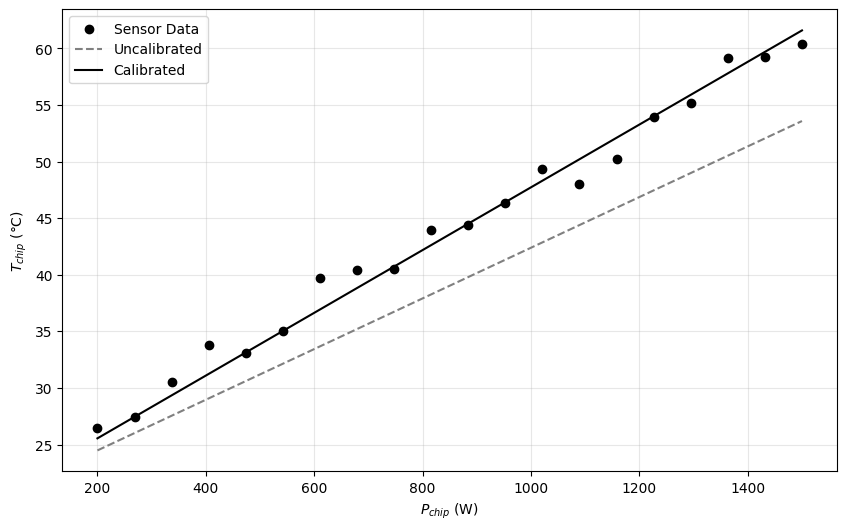

In [7]:
# ==============================
# Inputs
# ==============================
np.random.seed(42)
true_UA = 38.5  # The physical system has a degraded UA
actual_system = ThermalModel(UA_design=true_UA)
powers_W = np.linspace(200, 1500, 20) # Generate a variety of operating conditions
m_dot_kg_s = 0.05
T_in_C = 20.0
initial_guess = [50.0] # The design value for UA. 

# ==============================
# Sensor measurements 
# ==============================
sensor_T_chip = []
for Q in powers_W:
    _, actual_T = actual_system.solve(Q, m_dot_kg_s, T_in_C)
    noise = np.random.normal(0, 1.5) # 1.5 °C standard deviation noise
    sensor_T_chip.append(actual_T + noise)

sensor_T_chip = np.array(sensor_T_chip)

# ==============================
# Calibration
# ==============================
def objective_function(UA_guess, powers, measured_temps):
    twin = ThermalModel(UA_design=UA_guess[0])
    error = 0
    for Q, T_meas in zip(powers, measured_temps):
        _, T_pred = twin.solve(Q, m_dot_kg_s, T_in_C)
        error += (T_pred - T_meas)**2
    return error

result = minimize(objective_function, initial_guess, args=(powers_W, sensor_T_chip), bounds=[(10, 100)])

calibrated_UA = result.x[0]
print(f"Original Design UA: 50.0 W/K")
print(f"True Physical UA: {true_UA} W/K")
print(f"Calibrated Digital Twin UA: {calibrated_UA:.2f} W/K")

# ==============================
# Plots
# ==============================
twin_calibrated = ThermalModel(UA_design=calibrated_UA)
T_chip_design = [design_model.solve(Q, m_dot_kg_s, T_in_C)[1] for Q in powers_W]
T_chip_twin = [twin_calibrated.solve(Q, m_dot_kg_s, T_in_C)[1] for Q in powers_W]

plt.figure(figsize=(10, 6))
plt.scatter(powers_W, sensor_T_chip, color='black', label='Sensor Data', zorder=3)
plt.plot(powers_W, T_chip_design, linestyle='--', color='gray', label='Uncalibrated')
plt.plot(powers_W, T_chip_twin, color='black', label='Calibrated')
plt.xlabel('$P_{chip}$ (W)')
plt.ylabel('$T_{chip}$ (°C)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('../lectures/figures/digital_twin_chip_temperature.pdf',dpi=300)
plt.show()

If a cooling distribution unit needs to proactively ramp up pump speeds in response to a sudden server load, the digital twin must predict the future chip temperature in a fraction of a second. If the calculation takes longer than the physical thermal time constant of the cold plate, the chip will throttle or fail before the cooling system can react.

In [9]:
start_time = time.perf_counter()

# Simulate a sudden spike to 2000W
_, emergency_T_chip = twin_calibrated.solve(Q=2000, m_dot=0.05, T_in=20.0)
end_time = time.perf_counter()
execution_time_ms = (end_time - start_time) * 1000

print(f"Predicted Emergency Temp: {emergency_T_chip:.2f} °C")
print(f"Computation Time: {execution_time_ms:.5f} ms")

Predicted Emergency Temp: 75.46 °C
Computation Time: 0.13029 ms


While this model executes quickly—allowing us to run hundreds of predictive scenarios instantly—we know that it is overly simplified. We treated the entire chip and cold plate assembly as a single lumped thermal node (a Biot analysis assumption). In modern high-power processors, severe temperature gradients exist, and hot spots can easily exceed critical thresholds even if the average lumped temperature looks safe. We need a model that captures the spatial distribution of heat within the chip, but we still need it to execute quickly. 